In [12]:
pip install arch

In [13]:
import pandas as pd
import numpy as np
from arch import arch_model

In [14]:
excel_file_path = 'VAR Model_Satyadeep.xlsx'
df = pd.read_excel(excel_file_path)
display(df.head())

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25
0,NaN,NaN,Cipla,NaN,NaN,NaN,ONGC,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,Date,Price,Returns,Quantity,Total Val,Price,Returns,Quantity,Total Val,...,MTM from amt invested,Portfolio Returns,NaN,Nifty 50,Returns,NaN,NaN,NaN,NaN,NaN
2,NaN,2026-09-03 00:00:00,1325,0.002872,25,33125,270.8,-0.029652,150,40620,...,-2015.5,-0.018103,NaN,24028.05,-0.017427,NaN,Portfolio Stats,NaN,NaN,NaN
3,NaN,2026-06-03 00:00:00,1321.2,-0.003928,25,33030,278.95,0.009364,150,41842.5,...,936,0.008366,NaN,24450.45,-0.012819,NaN,Mean,41.228217,NaN,NaN
4,NaN,2026-05-03 00:00:00,1326.4,0.010002,25,33160,276.35,-0.002169,150,41452.5,...,1292,0.011664,NaN,24765.9,0.011591,NaN,Variance,832243.211319,NaN,NaN


In [15]:
portfolio_returns = df['Unnamed: 17'][2:].dropna().astype(float).iloc[::-1].reset_index(drop=True) * 100
portfolio_returns

,Unnamed: 17
0,-0.366498
1,-1.231408
2,0.625585
3,1.859475
4,-0.236317
...,...
1728,1.073010
1729,-2.080895
1730,1.166431
1731,0.836612


In [16]:
# 3. Fit the GARCH(1,1) Model
# We use Student's t-distribution ('t') to handle the "Fat Tails" of real stock data
am = arch_model(portfolio_returns, vol='Garch', p=1, q=1, dist='t')
res = am.fit(update_freq=5, disp='off')

# 4. Get the 1-Day Forecast
forecasts = res.forecast(horizon=1)
cond_mean = forecasts.mean.iloc[-1]
cond_var = forecasts.variance.iloc[-1]
cond_std = np.sqrt(cond_var)

# 5. Calculate VaR using the distribution's quantiles
# ppf is the Percent Point Function (inverse of CDF)
# For 95% VaR, we look at the 0.05 quantile
q = am.distribution.ppf([0.05], res.params[-1:]) # res.params[-1:] is the 'nu' (degrees of freedom)
var_95 = (cond_mean + q * cond_std).values[0]

# 6. Translate to Currency
portfolio_value = 110000 # Your position
var_amount = (var_95 / 100) * portfolio_value

print(f"95% 1-Day GARCH VaR: {abs(var_amount):,.2f}")

95% 1-Day GARCH VaR: 2,236.75


In [17]:
from arch import arch_model

# Scaling by 100 is standard practice to help the model converge
am = arch_model(portfolio_returns, vol='Garch', p=1, q=1, dist='t')
res = am.fit(update_freq=5)

print(res.summary())

Iteration:      5,   Func. Count:     41,   Neg. LLF: 52662.53197177037
Iteration:     10,   Func. Count:     76,   Neg. LLF: 2862.6278043956545
Iteration:     15,   Func. Count:    108,   Neg. LLF: 2862.334169309969
Optimization terminated successfully    (Exit mode 0)
            Current function value: 2862.3341693099787
            Iterations: 15
            Function evaluations: 108
            Gradient evaluations: 15
                        Constant Mean - GARCH Model Results                         
Dep. Variable:                  Unnamed: 17   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -2862.33
Distribution:      Standardized Student's t   AIC:                           5734.67
Method:                  Maximum Likelihood   BIC:                           5761.96
                                              No. Observations

In [18]:
# 1. Forecast the next day's variance
# Horizon=1 means we are looking at 'tomorrow'
forecast = res.forecast(horizon=1)
cond_mean = forecast.mean.iloc[-1].values[0]
cond_var = forecast.variance.iloc[-1].values[0]
cond_std = np.sqrt(cond_var)

# 2. VaR Parameters (95% Confidence)
q = am.distribution.ppf([0.05], res.params[-1:])[0]
portfolio_value = 110000 # ₹1.1 Lakhs

# 3. VaR Calculation
# VaR = mean + t-quantile x volatility
var_95_pct = cond_mean + (q * cond_std)
var_amount = (var_95_pct / 100) * portfolio_value

print(f"Forecasted Mean: {cond_mean:.4f}%")
print(f"Forecasted Volatility (Sigma): {cond_std:.4f}%")
print(f"--- 95% 1-Day Value at Risk: ₹{abs(var_amount):,.2f} ---")

Forecasted Mean: 0.0692%
Forecasted Volatility (Sigma): 1.3394%
--- 95% 1-Day Value at Risk: ₹2,236.75 ---


--- Backtest Results (1,733 Days) ---
Expected Breaches (5%): 87
Actual Breaches: 89
Breach Ratio: 0.0514


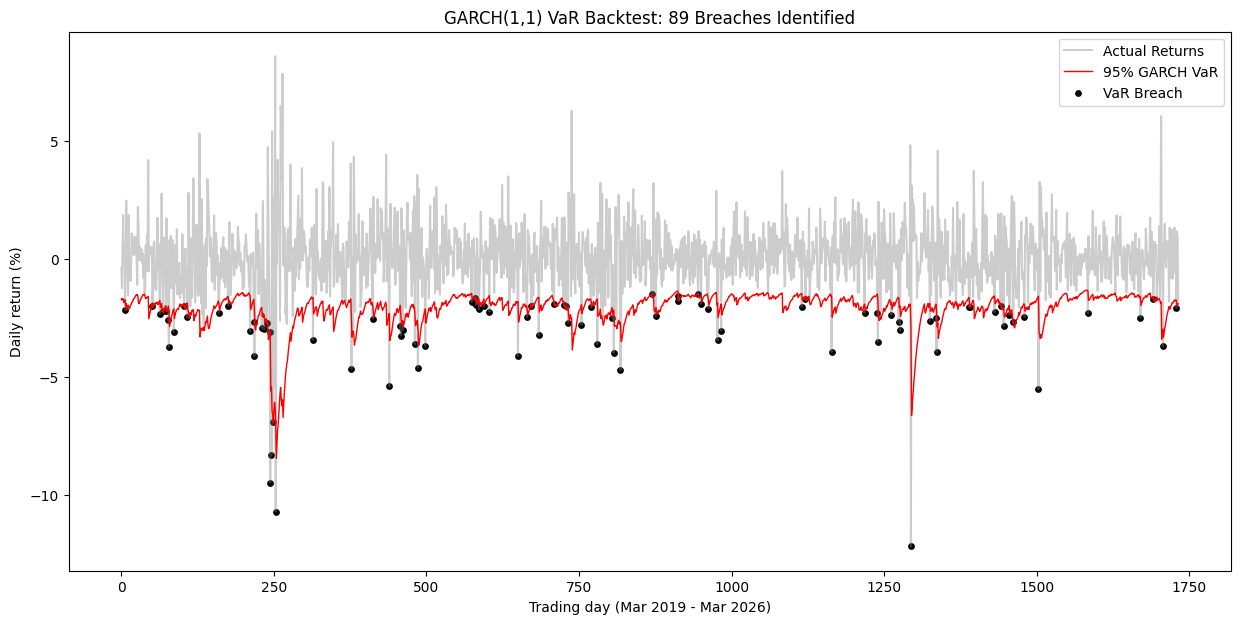

In [22]:
from matplotlib import pyplot as plt

# 1. Extract Conditional Volatility and Mean from your 'res' object
# The 'arch' library stores these in the 'conditional_volatility' and 'params'
df_backtest = pd.DataFrame(index=portfolio_returns.index)
df_backtest['Actual_Returns'] = portfolio_returns
df_backtest['Cond_Vol'] = res.conditional_volatility
mu = res.params['mu']

# 2. Calculate the 95% VaR threshold for every day
# Use the Student-t quantile to match the fitted model (not the Normal 1.645)
q = am.distribution.ppf([0.05], res.params[-1:])[0]
df_backtest['VaR_95'] = mu + (q * df_backtest['Cond_Vol'])

# 3. Identify Breaches (Days where Actual Return was WORSE than VaR)
df_backtest['Breach'] = df_backtest['Actual_Returns'] < df_backtest['VaR_95']

# 4. Calculate Statistics
total_obs = len(df_backtest)
actual_breaches = df_backtest['Breach'].sum()
breach_ratio = actual_breaches / total_obs
expected_breaches = 0.05 * total_obs

print(f"--- Backtest Results (1,733 Days) ---")
print(f"Expected Breaches (5%): {expected_breaches:.0f}")
print(f"Actual Breaches: {actual_breaches}")
print(f"Breach Ratio: {breach_ratio:.4f}")

# 5. Visualization
plt.figure(figsize=(15, 7))
plt.plot(df_backtest.index, df_backtest['Actual_Returns'], color='gray', alpha=0.4, label='Actual Returns')
plt.plot(df_backtest.index, df_backtest['VaR_95'], color='red', label='95% GARCH VaR', linewidth=1)

# Mark the breaches with black dots
breach_points = df_backtest[df_backtest['Breach']]
plt.scatter(breach_points.index, breach_points['Actual_Returns'], color='black', s=15, label='VaR Breach')

plt.title(f'GARCH(1,1) VaR Backtest: {actual_breaches} Breaches Identified')
plt.legend()
plt.xlabel('Trading day (Mar 2019 - Mar 2026)')
plt.ylabel('Daily return (%)')
plt.savefig('var_backtest.png', dpi=150, bbox_inches='tight')
plt.show()

In [20]:
from arch import arch_model

# 1. Fit the Normal Distribution Model
model_norm = arch_model(portfolio_returns, vol='Garch', p=1, q=1, dist='normal')
res_norm = model_norm.fit(disp='off')

# 2. Fit the Student's t-Distribution Model
model_t = arch_model(portfolio_returns, vol='Garch', p=1, q=1, dist='t')
res_t = model_t.fit(disp='off')

# 3. Create Comparison Table
comparison = pd.DataFrame({
    'Model': ['GARCH (Normal)', 'GARCH (Student-t)'],
    'AIC': [res_norm.aic, res_t.aic],
    'BIC': [res_norm.bic, res_t.bic],
    'Log-Likelihood': [res_norm.loglikelihood, res_t.loglikelihood]
})

print("--- Model Selection Criteria ---")
print(comparison)

# 4. Logic to identify the winner
winner = comparison.loc[comparison['AIC'].idxmin(), 'Model']
print(f"\nRecommended Model based on AIC: {winner}")

--- Model Selection Criteria ---
               Model          AIC          BIC  Log-Likelihood
0     GARCH (Normal)  5859.962849  5881.793286    -2925.981424
1  GARCH (Student-t)  5734.668339  5761.956385    -2862.334169

Recommended Model based on AIC: GARCH (Student-t)


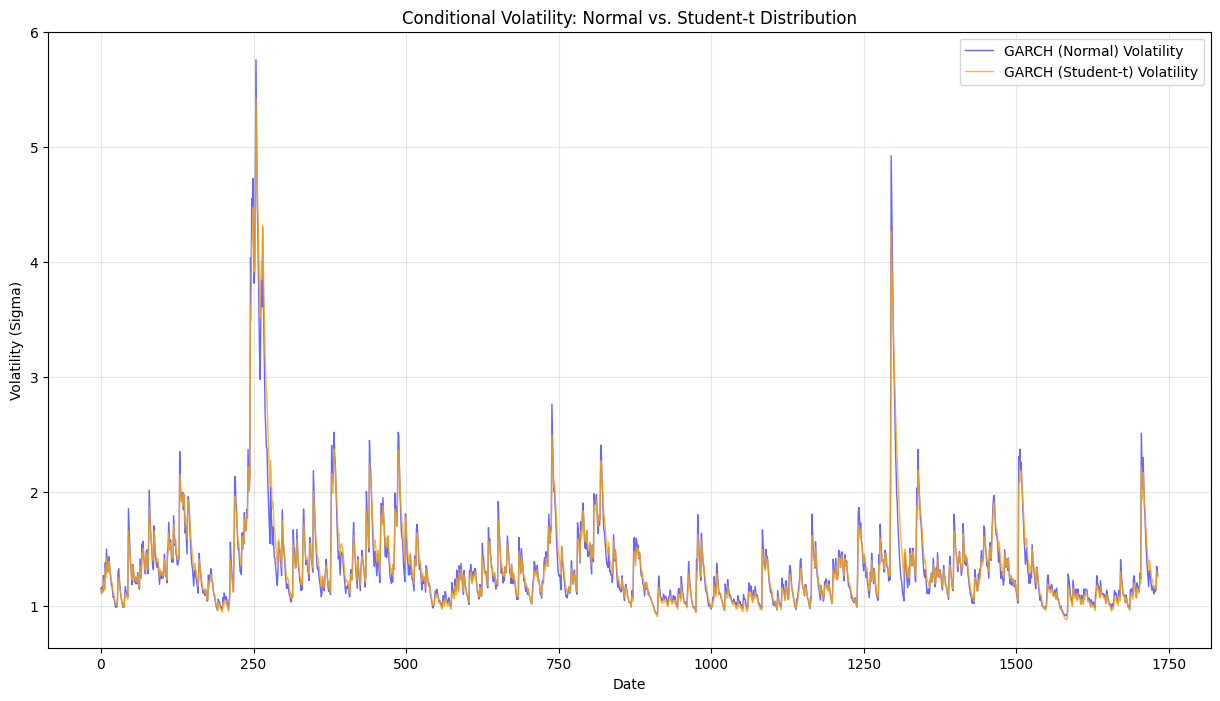

Avg Volatility (Normal): 1.3571
Avg Volatility (Student-t): 1.3632


In [21]:
import matplotlib.pyplot as plt

# 1. Extract the conditional volatility from both results
vol_norm = res_norm.conditional_volatility
vol_t = res_t.conditional_volatility

# 2. Plotting
plt.figure(figsize=(15, 8))

plt.plot(vol_norm.index, vol_norm, color='blue', alpha=0.6, label='GARCH (Normal) Volatility', linewidth=1)
plt.plot(vol_t.index, vol_t, color='orange', alpha=0.8, label='GARCH (Student-t) Volatility', linewidth=1)

plt.title('Conditional Volatility: Normal vs. Student-t Distribution')
plt.ylabel('Volatility (Sigma)')
plt.xlabel('Trading day (Mar 2019 - Mar 2026)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('volatility_normal_vs_t.png'  , dpi=150, bbox_inches='tight')
plt.show()

# 3. Print the average volatility of each
print(f"Avg Volatility (Normal): {vol_norm.mean():.4f}")
print(f"Avg Volatility (Student-t): {vol_t.mean():.4f}")